<a href="https://colab.research.google.com/github/HARSHINI-K345/Fake-News-Detection-BERT/blob/main/GA_DNN%2BXG(pub1)_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
!pip install xgboost

In [36]:
!pip install scipy

In [19]:
%pip install --upgrade scipy tensorflow

import numpy as np
import pandas as pd
import random
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
pip install lime

In [23]:
from google.colab import files
import os

print("Please upload 'xAPI-Edu-Dataset Expansion.xlsx' below:")
uploaded = files.upload()

# Confirm the file is uploaded and available in the working directory
if os.path.exists("xAPI-Edu-Dataset Expansion.xlsx"):
    print("\nSuccess! 'xAPI-Edu-Dataset Expansion.xlsx' uploaded successfully and ready for use.")
else:
    print("\nFile not found. Please ensure you uploaded the file with the exact name 'xAPI-Edu-Dataset Expansion.xlsx'.")

Please upload 'xAPI-Edu-Dataset Expansion.xlsx' below:


Saving xAPI-Edu-Dataset Expansion.xlsx to xAPI-Edu-Dataset Expansion.xlsx

Success! 'xAPI-Edu-Dataset Expansion.xlsx' uploaded successfully and ready for use.


In [7]:
import shap
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt

In [8]:
# reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [21]:
DATA_PATH = "xAPI-Edu-Dataset Expansion.xlsx"
TEST_SIZE = 0.3
POP_SIZE = 10        # keep small for faster run (increase for more tuning)
GENERATIONS = 10
MUTATION_RATE = 0.2
EPOCHS = 60
PATIENCE = 8

In [24]:
# ---------- Load & preprocess ----------
df = pd.read_excel(DATA_PATH)

# feature engineering
df["engagement"] = df["raisedhands"] + df["VisITedResources"] + df["AnnouncementsView"] + df["Discussion"]
df["resource_per_hand"] = (df["VisITedResources"]+1) / (df["raisedhands"]+1)

from sklearn.impute import SimpleImputer

# encode target
y = LabelEncoder().fit_transform(df['Class'])
X = df.drop(columns=['Class'])
X = pd.get_dummies(X, drop_first=True)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# split train/test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=TEST_SIZE,
                                                    stratify=y, random_state=SEED)

# balance with SMOTE
sm = SMOTE(random_state=SEED)
X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train)

In [25]:
# ---------- Build DNN ----------
def build_model(input_dim, params):
    model = models.Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    for n in params["neurons"][:params["n_layers"]]:
        model.add(layers.Dense(n, activation=params["activation"]))
        if params["dropout"] > 0:
            model.add(layers.Dropout(params["dropout"]))
    model.add(layers.Dense(3, activation="softmax"))
    opt = optimizers.Adam(learning_rate=params["lr"])
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

In [26]:
# ---------- GA encoding ----------
def random_params():
    return {
        "n_layers": random.choice([1, 2, 3]),
        "neurons": [random.randint(32, 128) for _ in range(3)],
        "activation": random.choice(["relu", "tanh"]),
        "dropout": round(random.uniform(0.0, 0.4), 2),
        "lr": 10 ** random.uniform(-3.5, -2),   # ~0.0003–0.01
        "batch_size": random.choice([16, 32, 64])
    }
def mutate(params):
    if random.random() < MUTATION_RATE:
        params["neurons"][random.randint(0, 2)] = random.randint(32, 128)
    if random.random() < MUTATION_RATE:
        params["lr"] = 10 ** random.uniform(-3.5, -2)
    if random.random() < MUTATION_RATE:
        params["activation"] = random.choice(["relu", "tanh"])
    if random.random() < MUTATION_RATE:
        params["dropout"] = round(random.uniform(0.0, 0.4), 2)
    return params

In [27]:
# ---------- GA Fitness ----------
def fitness(params, X_train, y_train, X_val, y_val):
    model = build_model(X_train.shape[1], params)
    es = callbacks.EarlyStopping(monitor="val_accuracy", patience=PATIENCE,
                                 restore_best_weights=True, mode="max", verbose=0)
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=EPOCHS, batch_size=params["batch_size"],
                  verbose=0, callbacks=[es])
    return max(h.history["val_accuracy"])

In [29]:
# ---------- GA Run ----------
def run_ga(X_train, y_train):
    # split validation
    split = int(0.8 * len(X_train))
    X_tr, X_val = X_train[:split], X_train[split:]
    y_tr, y_val = y_train[:split], y_train[split:]

    # init population
    population = [random_params() for _ in range(POP_SIZE)]
    scores = [fitness(p, X_tr, y_tr, X_val, y_val) for p in population]

    for g in range(GENERATIONS):
        new_pop = []
        for _ in range(POP_SIZE):
            p1, p2 = random.sample(population, 2)
            child = {k: (p1[k] if random.random() < 0.5 else p2[k]) for k in p1}
            child = mutate(child)
            new_pop.append(child)
        new_scores = [fitness(p, X_tr, y_tr, X_val, y_val) for p in new_pop]

        # elitism: keep top
        combined = population + new_pop
        combined_scores = scores + new_scores
        best_indices = np.argsort(combined_scores)[-POP_SIZE:]
        population = [combined[i] for i in best_indices]
        scores = [combined_scores[i] for i in best_indices]
        print(f"Gen {g+1}/{GENERATIONS}, best val acc: {max(scores):.4f}")

    best_idx = np.argmax(scores)
    return population[best_idx]

# ---------- Train GA-DNN ----------
print("Running GA to find best DNN params...")
# Fix: Remove samples with label 3 from y_train_bal and corresponding X_train_bal rows
mask = y_train_bal < 3
X_train_bal_fixed = X_train_bal[mask]
y_train_bal_fixed = y_train_bal[mask]

best_params = run_ga(X_train_bal_fixed, y_train_bal_fixed)
print("Best GA-DNN hyperparams:", best_params)

dnn_model = build_model(X_train_bal_fixed.shape[1], best_params)
es = callbacks.EarlyStopping(monitor="val_accuracy", patience=PATIENCE,
                             restore_best_weights=True, mode="max", verbose=1)
dnn_model.fit(X_train_bal_fixed, y_train_bal_fixed, validation_split=0.2,
              epochs=EPOCHS, batch_size=best_params["batch_size"],
              verbose=0, callbacks=[es])

Running GA to find best DNN params...
Gen 1/10, best val acc: 1.0000
Gen 2/10, best val acc: 1.0000
Gen 3/10, best val acc: 1.0000
Gen 4/10, best val acc: 1.0000
Gen 5/10, best val acc: 1.0000
Gen 6/10, best val acc: 1.0000
Gen 7/10, best val acc: 1.0000
Gen 8/10, best val acc: 1.0000
Gen 9/10, best val acc: 1.0000
Gen 10/10, best val acc: 1.0000
Best GA-DNN hyperparams: {'n_layers': 3, 'neurons': [60, 92, 77], 'activation': 'relu', 'dropout': 0.27, 'lr': 0.0009323756995716771, 'batch_size': 64}
Epoch 21: early stopping
Restoring model weights from the end of the best epoch: 13.


In [30]:
# ---------- Train XGBoost ----------
xgb = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=SEED,
    eval_metric="mlogloss"
)
xgb.fit(X_train_bal, y_train_bal)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.03, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=500, n_jobs=None,
              num_parallel_tree=None, ...)

In [31]:
# ---------- Ensemble Predictions ----------
probs_dnn = dnn_model.predict(X_test)
probs_xgb = xgb.predict_proba(X_test)

# Align shapes: use only first 3 columns of XGBoost (classes 0,1,2)
probs_xgb_aligned = probs_xgb[:, :3]

# weighted ensemble (favor XGBoost more)
final_probs = (0.7 * probs_xgb_aligned + 0.3 * probs_dnn)
final_preds = np.argmax(final_probs, axis=1)

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [32]:
# ---------- Evaluate ----------
acc = accuracy_score(y_test, final_preds)
print("Final Ensemble Accuracy:", acc)
print("\nClassification Report:\n", classification_report(y_test, final_preds))
print("Confusion Matrix:\n", confusion_matrix(y_test, final_preds))

Final Ensemble Accuracy: 0.916256157635468

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       219
           1       0.76      0.98      0.85       202
           2       0.98      0.99      0.99       330
           3       0.00      0.00      0.00        61

    accuracy                           0.92       812
   macro avg       0.69      0.74      0.71       812
weighted avg       0.86      0.92      0.88       812

Confusion Matrix:
 [[219   0   0   0]
 [  0 197   5   0]
 [  0   2 328   0]
 [  0  61   0   0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


/tmp/ipykernel_812/4197958005.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test[:50], feature_names=X.columns)


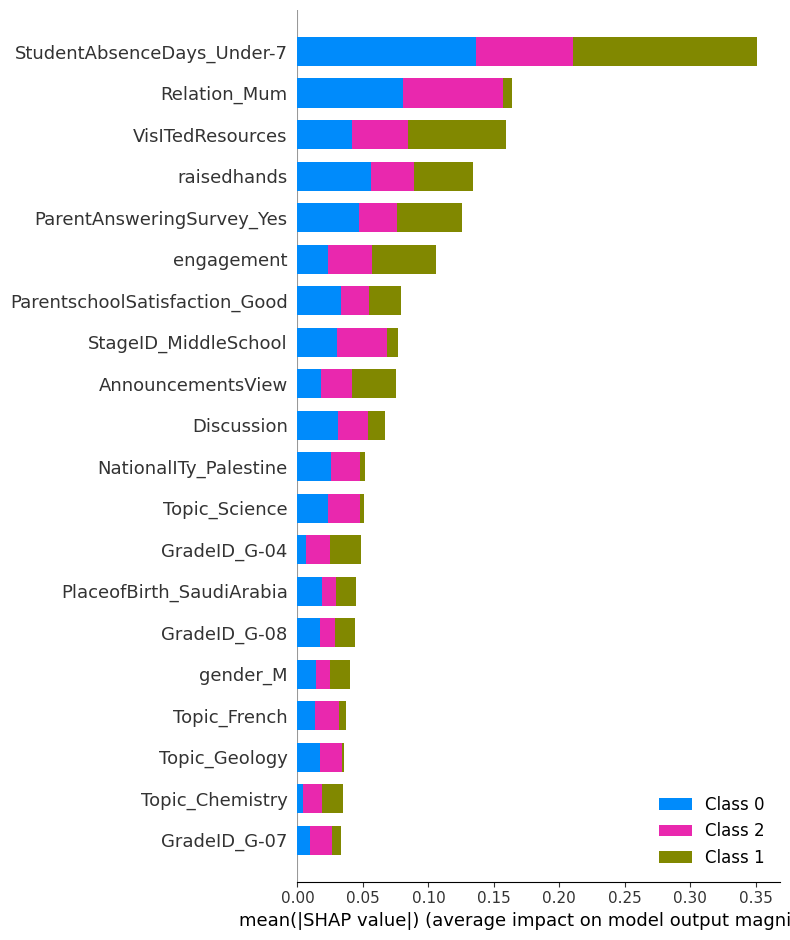

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [33]:
# ============================================
# STEP 9: Explainable AI (SHAP + LIME)
# ============================================

# 🔹 SHAP
explainer = shap.Explainer(dnn_model, X_train)
shap_values = explainer(X_test[:50])
shap.summary_plot(shap_values, X_test[:50], feature_names=X.columns)

# 🔹 LIME
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train,
    feature_names=X.columns,
    class_names=["Low","Medium","High"],
    mode="classification"
)
i = 10
exp = lime_explainer.explain_instance(X_test[i], dnn_model.predict, num_features=5)
exp.save_to_file("lime_explanation1.html")


,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15.0,16.0,2.0,20.0,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20.0,20.0,3.0,25.0,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10.0,7.0,0.0,30.0,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30.0,25.0,5.0,35.0,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40.0,50.0,12.0,50.0,No,Bad,Above-7,M


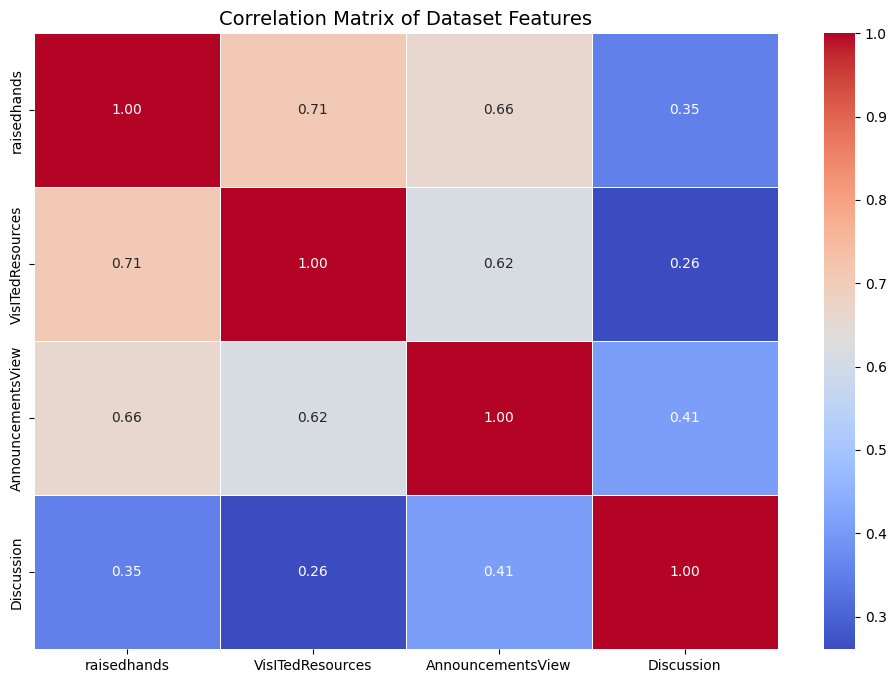

In [34]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset using the global configured DATA_PATH
data = pd.read_excel(DATA_PATH)

# Display first few rows (optional)
display(data.head())

# Compute correlation matrix
corr_matrix = data.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Matrix of Dataset Features", fontsize=14)
plt.show()